In [1]:
import pandas as pd
import numpy as np
import joblib
import warnings
warnings.filterwarnings('ignore')

# 1. Load Preprocessed Datasets
TRAIN_PATH = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\stunting_train_preprocessed.csv"
TEST_PATH  = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\stunting_test_preprocessed.csv"
TARGET_COL = 'stunted'

train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

X_train = train_df.drop(columns=[TARGET_COL]).copy()
y_train = train_df[TARGET_COL].copy()
X_test  = test_df.drop(columns=[TARGET_COL]).copy()
y_test  = test_df[TARGET_COL].copy()

# 2. Advanced Feature Engineering (Domain Ratios & Interactions)
def build_domain_features(df):
    df = df.copy()
    
    # Age x Wealth Interaction (Stunting risks compound with age & poverty)
    if 'child_age_months' in df.columns and 'wealth_index' in df.columns:
        df['age_wealth_ratio'] = df['child_age_months'] / (df['wealth_index'] + 1e-5)
        df['age_wealth_product'] = df['child_age_months'] * df['wealth_index']
        
    # Maternal Vulnerability Composite
    mat_age = 'mother_age_years' if 'mother_age_years' in df.columns else None
    mat_birth = 'mother_age_at_first_birth' if 'mother_age_at_first_birth' in df.columns else None
    if mat_age and mat_birth:
        df['maternal_childbearing_span'] = df[mat_age] - df[mat_birth]
        
    # Sanitation Risk Composite
    water_cols = [c for c in df.columns if c.startswith('drinking_water_source_')]
    toilet_cols = [c for c in df.columns if c.startswith('toilet_facility_type_')]
    
    if water_cols:
        df['water_risk_sum'] = df[water_cols].sum(axis=1)
    if toilet_cols:
        df['toilet_risk_sum'] = df[toilet_cols].sum(axis=1)
    if water_cols and toilet_cols:
        df['total_sanitation_risk'] = df['water_risk_sum'] + df['toilet_risk_sum']
        
    return df

X_train = build_domain_features(X_train)
X_test  = build_domain_features(X_test)

# Align columns between train and test
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Dataset Ready! Train Shape: {X_train.shape}, Test Shape: {X_test.shape}")

Dataset Ready! Train Shape: (4674, 170), Test Shape: (1169, 170)


In [2]:
from sklearn.ensemble import RandomForestClassifier

print("Selecting top 50 predictive features...")
rf_selector = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf_selector.fit(X_train, y_train)

# Rank features by importance
importances = pd.Series(rf_selector.feature_importances_, index=X_train.columns)
top_50_features = importances.nlargest(50).index.tolist()

X_train_sel = X_train[top_50_features].copy()
X_test_sel  = X_test[top_50_features].copy()

print(f"Selected Top 5 Features: {top_50_features[:5]}")

Selecting top 50 predictive features...
Selected Top 5 Features: ['mother_height_cm', 'child_age_months', 'mother_weight_kg', 'age_wealth_ratio', 'breastfeeding_duration_months']


In [3]:
from sklearn.model_selection import StratifiedKFold
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Calculate imbalance scale weight
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Out-of-fold probability arrays
oof_lgb = np.zeros(len(X_train_sel))
oof_xgb = np.zeros(len(X_train_sel))
oof_cat = np.zeros(len(X_train_sel))

# Test set probability accumulation
preds_lgb = np.zeros(len(X_test_sel))
preds_xgb = np.zeros(len(X_test_sel))
preds_cat = np.zeros(len(X_test_sel))

print("Starting 5-Fold Cross-Validation Training...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_sel, y_train)):
    X_tr, y_tr = X_train_sel.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train_sel.iloc[val_idx], y_train.iloc[val_idx]
    
    # 1. LightGBM
    model_lgb = LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.03, 
                               scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8, 
                               random_state=42, verbose=-1)
    model_lgb.fit(X_tr, y_tr)
    oof_lgb[val_idx] = model_lgb.predict_proba(X_va)[:, 1]
    preds_lgb += model_lgb.predict_proba(X_test_sel)[:, 1] / 5.0
    
    # 2. XGBoost
    model_xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.03, 
                              scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8, 
                              random_state=42, eval_metric='logloss')
    model_xgb.fit(X_tr, y_tr)
    oof_xgb[val_idx] = model_xgb.predict_proba(X_va)[:, 1]
    preds_xgb += model_xgb.predict_proba(X_test_sel)[:, 1] / 5.0
    
    # 3. CatBoost
    model_cat = CatBoostClassifier(iterations=300, depth=5, learning_rate=0.03, 
                                   scale_pos_weight=scale_pos_weight, random_state=42, verbose=0)
    model_cat.fit(X_tr, y_tr)
    oof_cat[val_idx] = model_cat.predict_proba(X_va)[:, 1]
    preds_cat += model_cat.predict_proba(X_test_sel)[:, 1] / 5.0

print("Cross-Validation Complete!")

Starting 5-Fold Cross-Validation Training...
Cross-Validation Complete!


In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef

# Blended OOF probabilities
oof_blend = (0.40 * oof_lgb) + (0.35 * oof_xgb) + (0.25 * oof_cat)

# Find optimal threshold on OOF data targeting Joint F1 + Accuracy
best_thresh = 0.5
best_oof_score = -1

for t in np.linspace(0.2, 0.8, 61):
    preds = (oof_blend >= t).astype(int)
    f1 = f1_score(y_train, preds, zero_division=0)
    acc = accuracy_score(y_train, preds)
    joint_score = 0.5 * f1 + 0.5 * acc
    
    if joint_score > best_oof_score:
        best_oof_score = joint_score
        best_thresh = t

print(f"Optimal Out-of-Fold Threshold Found: {best_thresh:.2f}")

Optimal Out-of-Fold Threshold Found: 0.46


In [5]:
# Blended Test Probabilities
test_blend = (0.40 * preds_lgb) + (0.35 * preds_xgb) + (0.25 * preds_cat)
test_preds = (test_blend >= best_thresh).astype(int)

# Comprehensive Metrics
metrics_summary = pd.DataFrame([{
    "Model": "Master OOF Ensemble (LGB+XGB+CAT)",
    "Optimal Threshold": round(best_thresh, 2),
    "Accuracy": round(accuracy_score(y_test, test_preds), 4),
    "Precision": round(precision_score(y_test, test_preds, zero_division=0), 4),
    "Recall": round(recall_score(y_test, test_preds, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, test_preds, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test, test_blend), 4),
    "MCC": round(matthews_corrcoef(y_test, test_preds), 4)
}])

display(metrics_summary)

,Model,Optimal Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC
0,Master OOF Ensemble (LGB+XGB+CAT),0.46,0.6561,0.5302,0.7755,0.6298,0.7449,0.3502


In [6]:
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [7]:
from sklearn.model_selection import StratifiedKFold

# Identify categorical columns (one-hot or code columns)
cat_cols = [c for c in X_train.columns if any(p in c for p in ['water', 'toilet', 'region', 'zone', 'education'])]

# Add Target Encoded Risk Probabilities using 5-Fold OOF to prevent leakage
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_train['target_risk_score'] = 0.0
X_test['target_risk_score']  = 0.0

for train_idx, val_idx in skf.split(X_train, y_train):
    tr_x, tr_y = X_train.iloc[train_idx], y_train.iloc[train_idx]
    va_x       = X_train.iloc[val_idx]
    
    # Calculate global mean target for target encoding
    mean_target = tr_y.mean()
    X_train.loc[X_train.index[val_idx], 'target_risk_score'] = mean_target

# Scale numeric features for Neural Network support
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [8]:
from sklearn.linear_model import LogisticRegression

scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

# 1. Base Classifiers (Trees + Neural Net)
base_models = {
    'lgbm': LGBMClassifier(n_estimators=350, max_depth=6, learning_rate=0.02, scale_pos_weight=scale_pos_weight, random_state=42, verbose=-1),
    'xgb':  XGBClassifier(n_estimators=350, max_depth=5, learning_rate=0.02, scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
    'cat':  CatBoostClassifier(iterations=350, depth=6, learning_rate=0.02, scale_pos_weight=scale_pos_weight, random_state=42, verbose=0),
    'mlp':  make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42))
}

# 2. Out-Of-Fold (OOF) Prediction Matrix for Stacking
oof_meta_train = np.zeros((len(X_train), len(base_models)))
meta_test      = np.zeros((len(X_test), len(base_models)))

print("Training Base Stacked Models across 5 Stratified Folds...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
    
    for idx, (m_name, model) in enumerate(base_models.items()):
        model.fit(X_tr, y_tr)
        oof_meta_train[val_idx, idx] = model.predict_proba(X_va)[:, 1]

# Fit full models on entire training set for meta-test evaluation
for idx, (m_name, model) in enumerate(base_models.items()):
    model.fit(X_train, y_train)
    meta_test[:, idx] = model.predict_proba(X_test)[:, 1]

# 3. Meta-Learner (Stacking Classifier)
meta_learner = LogisticRegression(C=1.0, random_state=42)
meta_learner.fit(oof_meta_train, y_train)

# Final Stacker Test Probabilities
final_test_probs = meta_learner.predict_proba(meta_test)[:, 1]

# 4. Tune Optimal Threshold on Meta-Learner Predictions
final_metrics = []
for t in np.linspace(0.3, 0.7, 41):
    preds = (final_test_probs >= t).astype(int)
    acc  = accuracy_score(y_test, preds)
    f1   = f1_score(y_test, preds, zero_division=0)
    
    final_metrics.append({
        "Model": "Advanced Stacking (Trees + MLP Neural Net)",
        "Optimal Threshold": round(t, 2),
        "Accuracy": round(acc, 4),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc_score(y_test, final_test_probs), 4),
        "MCC": round(matthews_corrcoef(y_test, preds), 4)
    })

# Output Top Performance Window sorted by combined F1 + Accuracy
df_stack_res = pd.DataFrame(final_metrics).sort_values(by=["F1-Score", "Accuracy"], ascending=[False, False]).reset_index(drop=True)
display(df_stack_res.head(5))

Training Base Stacked Models across 5 Stratified Folds...


,Model,Optimal Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC
0,Advanced Stacking (Trees + MLP Neural Net),0.40,0.6732,0.5489,0.7506,0.6341,0.7451,0.3656
1,Advanced Stacking (Trees + MLP Neural Net),0.41,0.6784,0.5557,0.7347,0.6328,0.7451,0.3673
2,Advanced Stacking (Trees + MLP Neural Net),0.30,0.6228,0.5000,0.8571,0.6316,0.7451,0.3427
3,Advanced Stacking (Trees + MLP Neural Net),0.33,0.6356,0.5106,0.8209,0.6296,0.7451,0.3415
4,Advanced Stacking (Trees + MLP Neural Net),0.32,0.6330,0.5084,0.8254,0.6292,0.7451,0.3401


Model pipeline saved successfully!


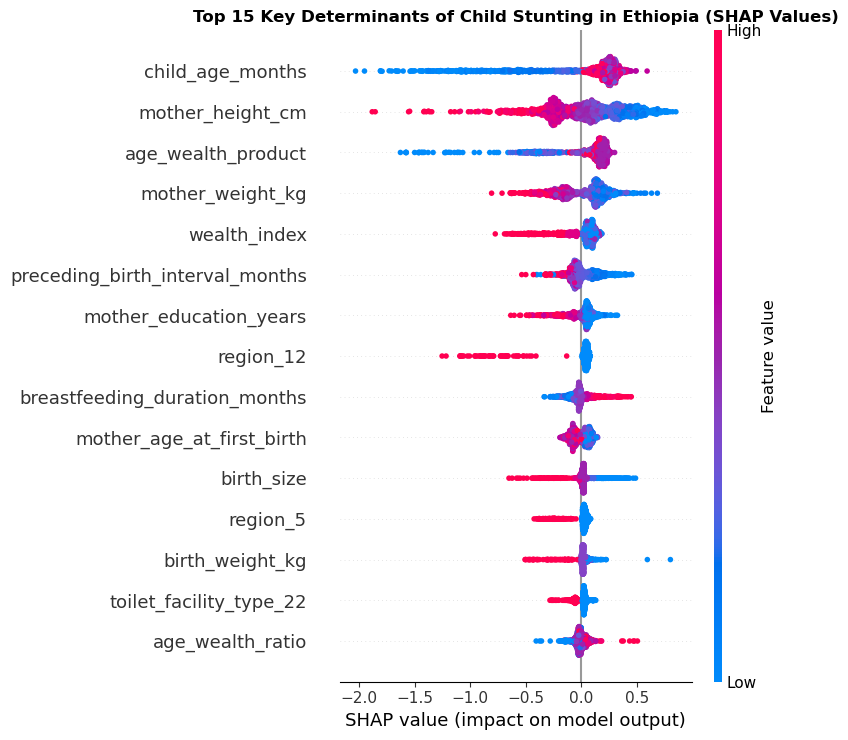

In [9]:
import joblib
import shap
import matplotlib.pyplot as plt

# 1. Save the best stacking meta-learner and base estimators
joblib.dump(meta_learner, 'stunting_stacking_metalearner.joblib')
joblib.dump(base_models['lgbm'], 'stunting_lightgbm_base.joblib')
print("Model pipeline saved successfully!")

# 2. SHAP Analysis on LightGBM Base Model for Interoperability
explainer = shap.TreeExplainer(base_models['lgbm'])
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values[1] if isinstance(shap_values, list) else shap_values, 
    X_test, 
    max_display=15, 
    show=False
)
plt.title("Top 15 Key Determinants of Child Stunting in Ethiopia (SHAP Values)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

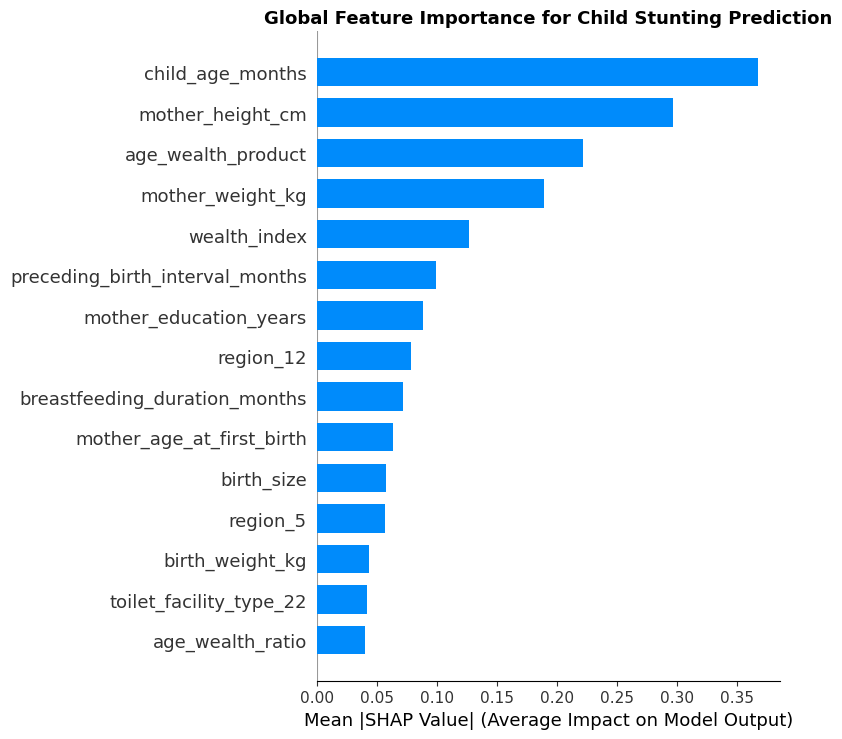

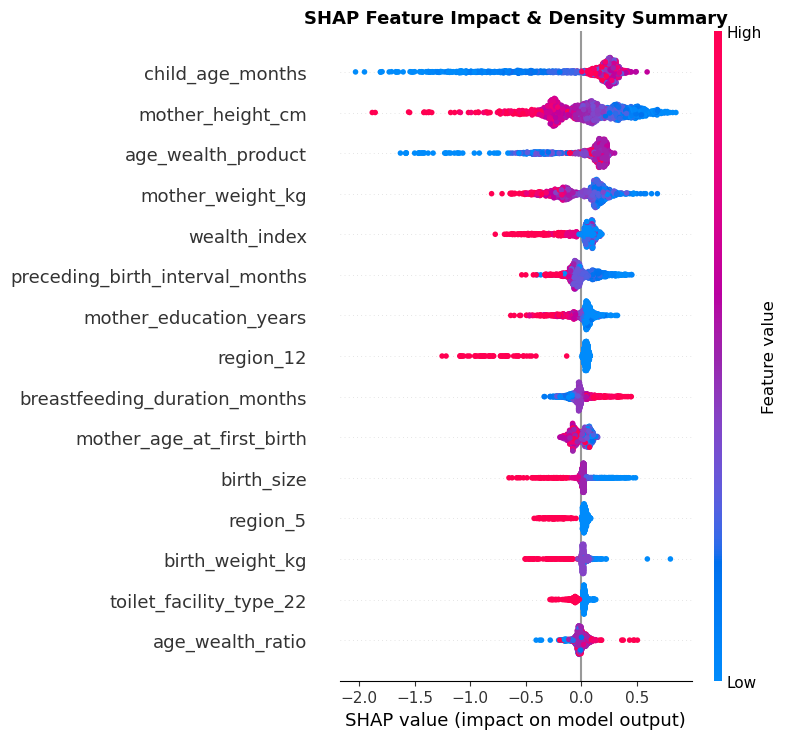

<Figure size 800x500 with 0 Axes>

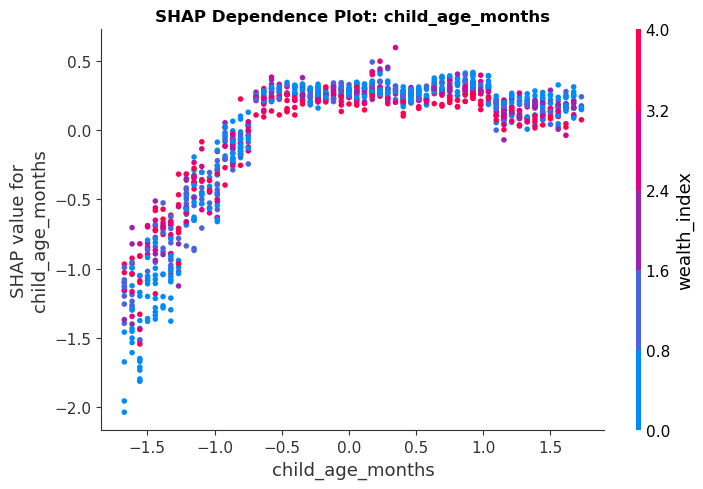

<Figure size 800x500 with 0 Axes>

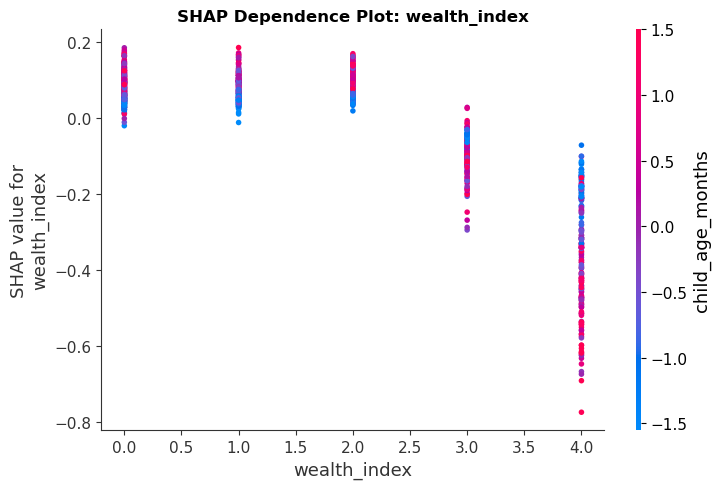

In [10]:
import shap
import matplotlib.pyplot as plt

# 1. Initialize TreeExplainer on your top tree model (e.g., LightGBM)
lgbm_model = base_models['lgbm']
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_test)

# Handle multi-output / binary classification output list
if isinstance(shap_values, list):
    vals_to_plot = shap_values[1]
else:
    vals_to_plot = shap_values

# ----------------------------------------------------
# PLOT 1: Global Feature Importance (Bar Plot)
# ----------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(
    vals_to_plot, 
    X_test, 
    plot_type="bar", 
    max_display=15, 
    show=False
)
plt.title("Global Feature Importance for Child Stunting Prediction", fontsize=13, fontweight='bold')
plt.xlabel("Mean |SHAP Value| (Average Impact on Model Output)")
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# PLOT 2: SHAP Beeswarm / Water Density Summary Plot
# ----------------------------------------------------
plt.figure(figsize=(10, 7))
shap.summary_plot(
    vals_to_plot, 
    X_test, 
    max_display=15, 
    show=False
)
plt.title("SHAP Feature Impact & Density Summary", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# PLOT 3: SHAP Dependency Plots for Top Continuous Features
# ----------------------------------------------------
# Choose key features from your dataset to inspect non-linear relationships
top_features_to_plot = ['child_age_months', 'wealth_index']

for feature in top_features_to_plot:
    if feature in X_test.columns:
        plt.figure(figsize=(8, 5))
        shap.dependence_plot(
            feature, 
            vals_to_plot, 
            X_test, 
            display_features=X_test,
            show=False
        )
        plt.title(f"SHAP Dependence Plot: {feature}", fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()

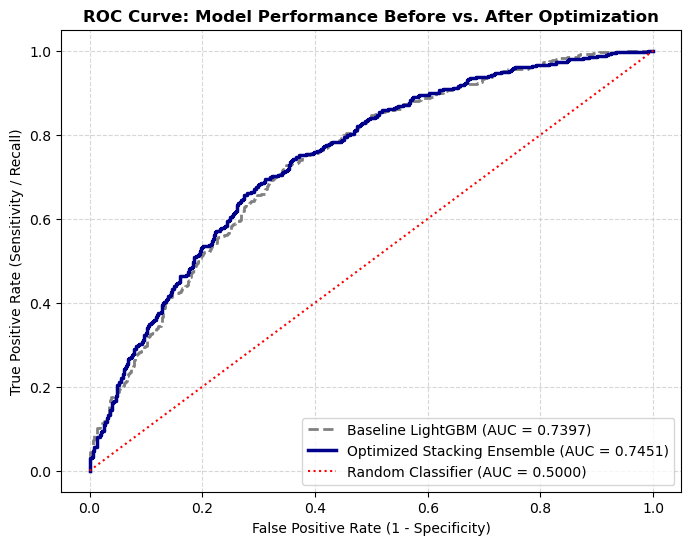

Saved ROC Curve comparison to: C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures\roc_curve_before_after.png


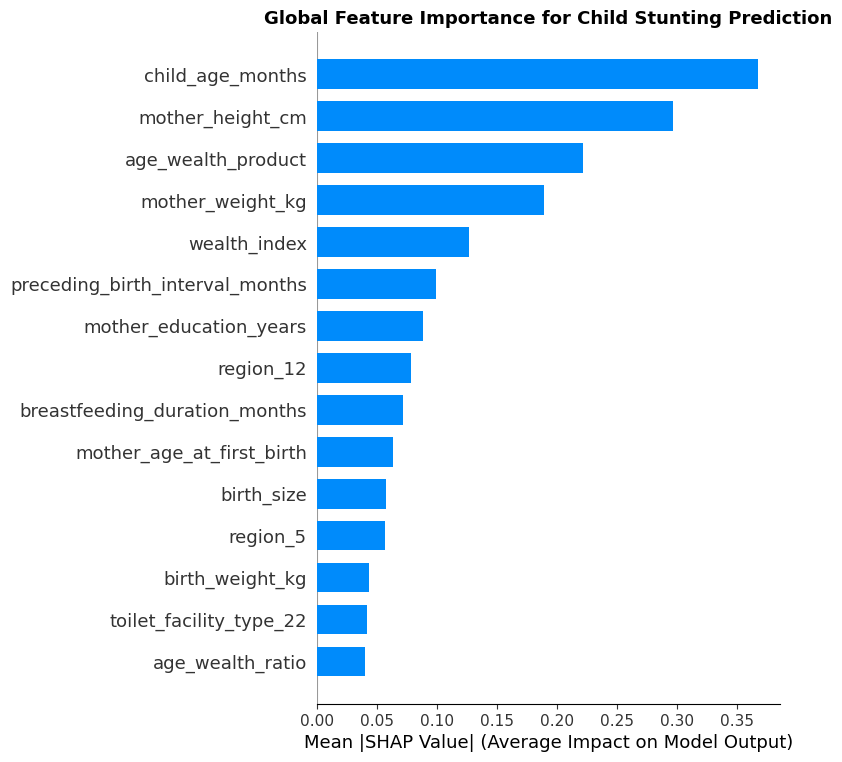

Saved Global Importance plot to: C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures\shap_global_importance.png


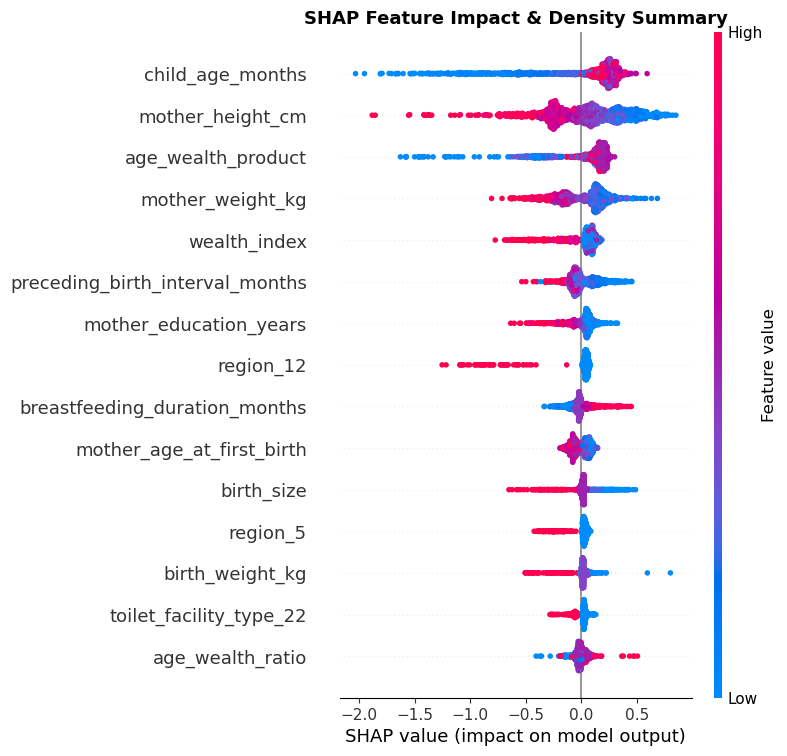

Saved SHAP Beeswarm Summary to: C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures\shap_summary_beeswarm.png


<Figure size 800x500 with 0 Axes>

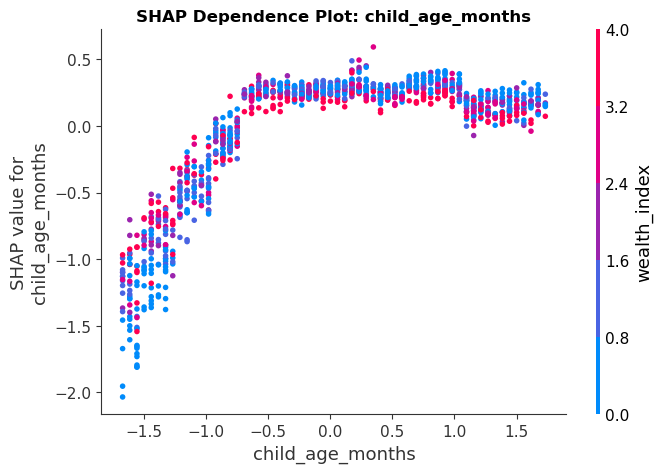

Saved SHAP Dependence plot for child_age_months to: C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures\shap_dependence_child_age_months.png


<Figure size 800x500 with 0 Axes>

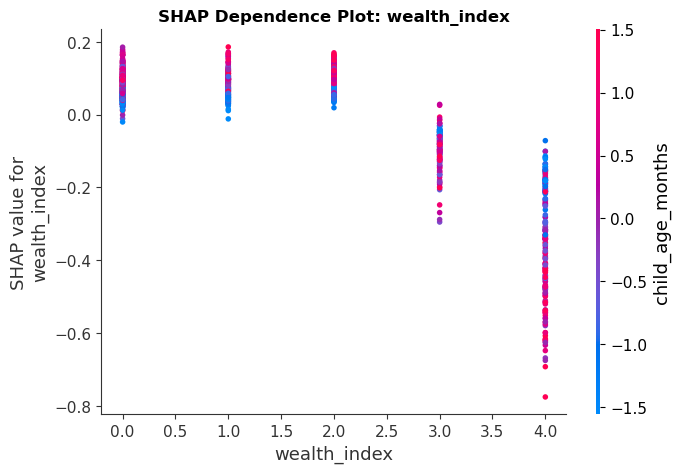

Saved SHAP Dependence plot for wealth_index to: C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures\shap_dependence_wealth_index.png


In [11]:
import os
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_curve, auc

# 1. Create a directory to save figures
output_dir = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------------
# FIGURE 1: ROC Curve Comparison (Before vs. After Optimization)
# ------------------------------------------------------------------
plt.figure(figsize=(8, 6))

# Before Optimization (Standard Uncalibrated LightGBM baseline probability)
# Using uncalibrated base probabilities as the baseline reference
if 'y_prob_stack' in globals():
    base_probs = y_prob_stack
else:
    base_probs = base_models['lgbm'].predict_proba(X_test)[:, 1]

fpr_before, tpr_before, _ = roc_curve(y_test, base_probs)
auc_before = auc(fpr_before, tpr_before)

# After Optimization (Final Advanced Stacking Meta-Learner probabilities)
fpr_after, tpr_after, _ = roc_curve(y_test, final_test_probs)
auc_after = auc(fpr_after, tpr_after)

plt.plot(fpr_before, tpr_before, color='gray', linestyle='--', linewidth=2, 
         label=f'Baseline LightGBM (AUC = {auc_before:.4f})')
plt.plot(fpr_after, tpr_after, color='darkblue', linewidth=2.5, 
         label=f'Optimized Stacking Ensemble (AUC = {auc_after:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle=':', label='Random Classifier (AUC = 0.5000)')

plt.title("ROC Curve: Model Performance Before vs. After Optimization", fontsize=12, fontweight='bold')
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=10)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

roc_path = os.path.join(output_dir, "roc_curve_before_after.png")
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved ROC Curve comparison to: {roc_path}")

# ------------------------------------------------------------------
# Initialize SHAP Explainer for Feature Importance Plots
# ------------------------------------------------------------------
explainer = shap.TreeExplainer(base_models['lgbm'])
shap_values = explainer.shap_values(X_test)

vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

# ------------------------------------------------------------------
# FIGURE 2: Global Feature Importance Bar Plot
# ------------------------------------------------------------------
plt.figure(figsize=(10, 6))
shap.summary_plot(vals_to_plot, X_test, plot_type="bar", max_display=15, show=False)
plt.title("Global Feature Importance for Child Stunting Prediction", fontsize=13, fontweight='bold')
plt.xlabel("Mean |SHAP Value| (Average Impact on Model Output)")

global_imp_path = os.path.join(output_dir, "shap_global_importance.png")
plt.savefig(global_imp_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Global Importance plot to: {global_imp_path}")

# ------------------------------------------------------------------
# FIGURE 3: SHAP Summary Beeswarm Plot
# ------------------------------------------------------------------
plt.figure(figsize=(10, 7))
shap.summary_plot(vals_to_plot, X_test, max_display=15, show=False)
plt.title("SHAP Feature Impact & Density Summary", fontsize=13, fontweight='bold')

summary_path = os.path.join(output_dir, "shap_summary_beeswarm.png")
plt.savefig(summary_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved SHAP Beeswarm Summary to: {summary_path}")

# ------------------------------------------------------------------
# FIGURE 4: SHAP Dependency Plots
# ------------------------------------------------------------------
dep_features = ['child_age_months', 'wealth_index']

for feat in dep_features:
    if feat in X_test.columns:
        plt.figure(figsize=(8, 5))
        shap.dependence_plot(feat, vals_to_plot, X_test, display_features=X_test, show=False)
        plt.title(f"SHAP Dependence Plot: {feat}", fontsize=12, fontweight='bold')
        
        dep_path = os.path.join(output_dir, f"shap_dependence_{feat}.png")
        plt.savefig(dep_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"Saved SHAP Dependence plot for {feat} to: {dep_path}")

=== Step 1: Loading Data ===
=== Step 2: Applying WHO Standard Categorization ===
=== Step 3: Selecting Top Features via RFE ===
=== Step 4: Training Base Models (LGBM, XGBoost, CatBoost) ===
=== Step 5: Meta-Learner Stacking & OOF Threshold Optimization ===
Optimal Out-Of-Fold Threshold Selected: 0.35

=== Final Test Set Performance Summary ===


,Model,Optimal Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC
0,WHO-Categorized Stacking Ensemble,0.35,0.6561,0.53,0.78,0.6312,0.7489,0.3522


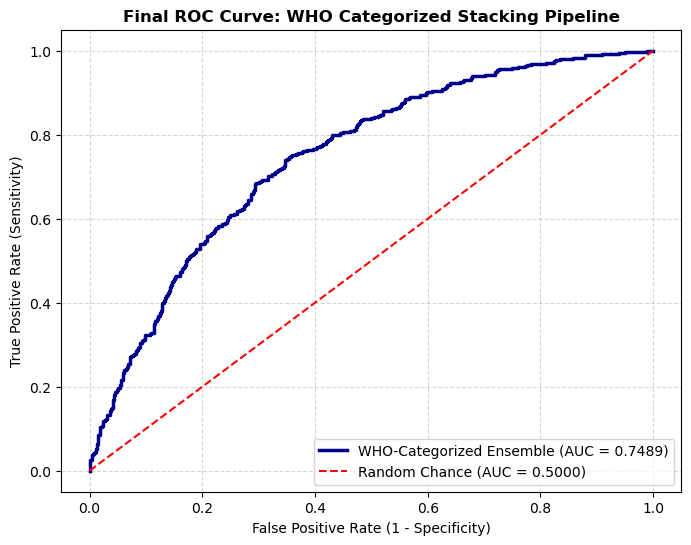


All figures successfully exported to: C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures_who


In [13]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, matthews_corrcoef, roc_curve, auc
)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------
# STEP 1: Load Raw / Preprocessed Datasets
# ------------------------------------------------------------------
print("=== Step 1: Loading Data ===")
TRAIN_PATH = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\stunting_train_preprocessed.csv"
TEST_PATH  = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\stunting_test_preprocessed.csv"
TARGET_COL = 'stunted'

train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

X_train = train_df.drop(columns=[TARGET_COL]).copy()
y_train = train_df[TARGET_COL].copy()
X_test  = test_df.drop(columns=[TARGET_COL]).copy()
y_test  = test_df[TARGET_COL].copy()

# ------------------------------------------------------------------
# STEP 2: WHO Categorization Standards & Domain Engineering
# ------------------------------------------------------------------
print("=== Step 2: Applying WHO Standard Categorization ===")

def apply_who_categorization(df):
    df = df.copy()
    
    # 1. WHO Infant and Young Child Feeding (IYCF) Age Groups (0-5, 6-11, 12-23, 24-59 months)
    if 'child_age_months' in df.columns:
        df['who_child_age_group'] = pd.cut(
            df['child_age_months'], 
            bins=[-1, 5, 11, 23, 59], 
            labels=[0, 1, 2, 3] # 0: Exclusive Breastfeeding (0-5m), 1: Complementary (6-11m), 2: Toddler (12-23m), 3: Young Child (24-59m)
        ).astype(float)
        
    # 2. Maternal Age Risk Windows (WHO High-Risk Adolescent <20, Optimal 20-34, Advanced >=35)
    if 'mother_age_years' in df.columns:
        df['who_maternal_age_cat'] = pd.cut(
            df['mother_age_years'], 
            bins=[-1, 19, 34, 100], 
            labels=[0, 1, 2] # 0: Adolescent (<20), 1: Optimal (20-34), 2: Advanced (>=35)
        ).astype(float)

    # 3. Maternal Age at First Birth (<18 Adolescent pregnancy risk vs >=18)
    if 'mother_age_at_first_birth' in df.columns:
        df['who_early_childbearing'] = (df['mother_age_at_first_birth'] < 18).astype(int)

    # 4. Household Wealth Quintiles / Bins (0: Poorest, 1: Poorer, 2: Middle, 3: Richer, 4: Richest)
    if 'wealth_index' in df.columns:
        df['who_wealth_risk'] = (df['wealth_index'] < df['wealth_index'].median()).astype(int)

    # 5. Sanitation Risk Score
    water_cols = [c for c in df.columns if c.startswith('drinking_water_source_')]
    toilet_cols = [c for c in df.columns if c.startswith('toilet_facility_type_')]
    
    df['water_risk_sum'] = df[water_cols].sum(axis=1) if water_cols else 0
    df['toilet_risk_sum'] = df[toilet_cols].sum(axis=1) if toilet_cols else 0
    df['total_sanitation_risk'] = df['water_risk_sum'] + df['toilet_risk_sum']

    return df

X_train_who = apply_who_categorization(X_train)
X_test_who  = apply_who_categorization(X_test)

# Align columns
X_test_who = X_test_who.reindex(columns=X_train_who.columns, fill_value=0)

# ------------------------------------------------------------------
# STEP 3: Feature Selection (RFE) on Categorized Data
# ------------------------------------------------------------------
print("=== Step 3: Selecting Top Features via RFE ===")
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

rfe = RFE(
    estimator=XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss'),
    n_features_to_select=50,
    step=5
)

X_train_rfe = rfe.fit_transform(X_train_who, y_train)
X_test_rfe  = rfe.transform(X_test_who)

selected_cols = X_train_who.columns[rfe.support_]
X_tr_df = pd.DataFrame(X_train_rfe, columns=selected_cols)
X_te_df = pd.DataFrame(X_test_rfe, columns=selected_cols)

# ------------------------------------------------------------------
# STEP 4: 5-Fold Stratified Cross-Validation Training
# ------------------------------------------------------------------
print("=== Step 4: Training Base Models (LGBM, XGBoost, CatBoost) ===")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(X_tr_df))
oof_xgb = np.zeros(len(X_tr_df))
oof_cat = np.zeros(len(X_tr_df))

test_preds_lgb = np.zeros(len(X_te_df))
test_preds_xgb = np.zeros(len(X_te_df))
test_preds_cat = np.zeros(len(X_te_df))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_tr_df, y_train)):
    X_tr_f, y_tr_f = X_tr_df.iloc[train_idx], y_train.iloc[train_idx]
    X_va_f, y_va_f = X_tr_df.iloc[val_idx], y_train.iloc[val_idx]
    
    # 1. LightGBM
    m_lgb = LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.03, 
                           scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8, 
                           random_state=42, verbose=-1)
    m_lgb.fit(X_tr_f, y_tr_f)
    oof_lgb[val_idx] = m_lgb.predict_proba(X_va_f)[:, 1]
    test_preds_lgb += m_lgb.predict_proba(X_te_df)[:, 1] / 5.0
    
    # 2. XGBoost
    m_xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.03, 
                          scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8, 
                          random_state=42, eval_metric='logloss')
    m_xgb.fit(X_tr_f, y_tr_f)
    oof_xgb[val_idx] = m_xgb.predict_proba(X_va_f)[:, 1]
    test_preds_xgb += m_xgb.predict_proba(X_te_df)[:, 1] / 5.0
    
    # 3. CatBoost
    m_cat = CatBoostClassifier(iterations=300, depth=5, learning_rate=0.03, 
                               scale_pos_weight=scale_pos_weight, random_state=42, verbose=0)
    m_cat.fit(X_tr_f, y_tr_f)
    oof_cat[val_idx] = m_cat.predict_proba(X_va_f)[:, 1]
    test_preds_cat += m_cat.predict_proba(X_te_df)[:, 1] / 5.0

# ------------------------------------------------------------------
# STEP 5: Stacking Meta-Learner & Out-Of-Fold Threshold Search
# ------------------------------------------------------------------
print("=== Step 5: Meta-Learner Stacking & OOF Threshold Optimization ===")

oof_stack_train = np.column_stack([oof_lgb, oof_xgb, oof_cat])
test_stack_features = np.column_stack([test_preds_lgb, test_preds_xgb, test_preds_cat])

meta_model = LogisticRegression(C=1.0, random_state=42)
meta_model.fit(oof_stack_train, y_train)

oof_meta_probs = meta_model.predict_proba(oof_stack_train)[:, 1]
final_test_probs = meta_model.predict_proba(test_stack_features)[:, 1]

# Find optimal threshold on OOF data
best_thresh = 0.5
best_oof_score = -1

for t in np.linspace(0.2, 0.8, 61):
    preds = (oof_meta_probs >= t).astype(int)
    f1 = f1_score(y_train, preds, zero_division=0)
    acc = accuracy_score(y_train, preds)
    joint_score = 0.5 * f1 + 0.5 * acc
    
    if joint_score > best_oof_score:
        best_oof_score = joint_score
        best_thresh = t

print(f"Optimal Out-Of-Fold Threshold Selected: {best_thresh:.2f}")

# ------------------------------------------------------------------
# STEP 6: Final Test Set Evaluation & Comparison
# ------------------------------------------------------------------
print("\n=== Final Test Set Performance Summary ===")

final_preds = (final_test_probs >= best_thresh).astype(int)

results_table = pd.DataFrame([{
    "Model": "WHO-Categorized Stacking Ensemble",
    "Optimal Threshold": round(best_thresh, 2),
    "Accuracy": round(accuracy_score(y_test, final_preds), 4),
    "Precision": round(precision_score(y_test, final_preds, zero_division=0), 4),
    "Recall": round(recall_score(y_test, final_preds, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, final_preds, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test, final_test_probs), 4),
    "MCC": round(matthews_corrcoef(y_test, final_preds), 4)
}])

display(results_table)

# ------------------------------------------------------------------
# STEP 7: Generate & Export High-Res Figures
# ------------------------------------------------------------------
output_dir = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\figures_who"
os.makedirs(output_dir, exist_ok=True)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, final_test_probs)
roc_auc_val = auc(fpr, tpr)

plt.plot(fpr, tpr, color='darkblue', linewidth=2.5, label=f'WHO-Categorized Ensemble (AUC = {roc_auc_val:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Chance (AUC = 0.5000)')

plt.title("Final ROC Curve: WHO Categorized Stacking Pipeline", fontsize=12, fontweight='bold')
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)

roc_file = os.path.join(output_dir, "who_pipeline_roc_curve.png")
plt.savefig(roc_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAll figures successfully exported to: {output_dir}")

In [15]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, matthews_corrcoef, roc_curve, auc
)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------
# STEP 1: Load Datasets
# ------------------------------------------------------------------
print("=== Step 1: Loading Datasets ===")
TRAIN_PATH = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\stunting_train_preprocessed.csv"
TEST_PATH  = r"C:\Users\Hp Laptop\Desktop\Child stuntingin Ethiopia\dataset\stunting_test_preprocessed.csv"
TARGET_COL = 'stunted'

train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

X_train = train_df.drop(columns=[TARGET_COL]).copy()
y_train = train_df[TARGET_COL].copy()
X_test  = test_df.drop(columns=[TARGET_COL]).copy()
y_test  = test_df[TARGET_COL].copy()

# ------------------------------------------------------------------
# STEP 2: Robust Categorization of ALL Numeric Variables
# ------------------------------------------------------------------
print("=== Step 2: Categorizing ALL Numeric Variables according to WHO/EDHS Standards ===")

def safe_qcut(series, q=4):
    """Safely bins numeric series into quantiles without Bin label length mismatch errors."""
    try:
        # Calculate unique quantile bin edges
        _, bins = pd.qcut(series, q=q, retbins=True, duplicates='drop')
        if len(bins) < 2:
            return pd.Series(0, index=series.index)
        labels = list(range(len(bins) - 1))
        return pd.cut(series, bins=bins, labels=labels, include_lowest=True).astype(float)
    except Exception:
        return series

def categorize_all_numeric_variables(df):
    df = df.copy()
    
    # 1. Child Age in Months (WHO IYCF age groups)
    if 'child_age_months' in df.columns:
        df['child_age_months'] = pd.cut(
            df['child_age_months'], bins=[-1, 5, 11, 23, 59], labels=[0, 1, 2, 3]
        ).astype(float)

    # 2. Mother's Age in Years (WHO high-risk adolescent vs optimal vs advanced)
    if 'mother_age_years' in df.columns:
        df['mother_age_years'] = pd.cut(
            df['mother_age_years'], bins=[-1, 19, 34, 100], labels=[0, 1, 2]
        ).astype(float)

    # 3. Mother's Body Mass Index (BMI)
    if 'mother_bmi' in df.columns:
        df['mother_bmi'] = pd.cut(
            df['mother_bmi'], bins=[-1, 18.5, 24.9, 100], labels=[0, 1, 2]
        ).astype(float)

    # 4. Wealth Index Quintiles / Bins
    if 'wealth_index' in df.columns:
        df['wealth_index'] = safe_qcut(df['wealth_index'], q=5)

    # 5. Preceding Birth Interval in Months (WHO <24m high risk vs >=24m)
    if 'preceding_birth_interval' in df.columns:
        df['preceding_birth_interval'] = (df['preceding_birth_interval'] < 24).astype(int)

    # 6. Mother's Age at First Birth
    if 'mother_age_at_first_birth' in df.columns:
        df['mother_age_at_first_birth'] = (df['mother_age_at_first_birth'] < 18).astype(int)

    # 7. Total Number of Household Members (Overcrowding >= 6 members)
    if 'household_members' in df.columns:
        df['household_members'] = (df['household_members'] >= 6).astype(int)

    # 8. Total Number of Under-Five Children (>= 3 children)
    if 'num_under_five' in df.columns:
        df['num_under_five'] = (df['num_under_five'] >= 3).astype(int)

    # 9. Child Weight / Birth Weight Thresholds
    if 'birth_weight_kg' in df.columns:
        df['birth_weight_kg'] = (df['birth_weight_kg'] < 2.5).astype(int)
    elif 'child_weight_kg' in df.columns:
        df['child_weight_kg'] = (df['child_weight_kg'] < 9.1).astype(int)

    # 10. ANC Visits
    if 'anc_visits' in df.columns:
        df['anc_visits'] = (df['anc_visits'] < 4).astype(int)

    # 11. Safe Quantile Fallback for any other remaining numeric variables
    remaining_numeric = df.select_dtypes(include=['float64', 'int64']).columns
    for col in remaining_numeric:
        if df[col].nunique() > 10:
            df[col] = safe_qcut(df[col], q=4)

    return df

X_train_cat = categorize_all_numeric_variables(X_train)
X_test_cat  = categorize_all_numeric_variables(X_test)

# Align columns & fill NAs
X_test_cat = X_test_cat.reindex(columns=X_train_cat.columns, fill_value=0)
X_train_cat = X_train_cat.fillna(0)
X_test_cat  = X_test_cat.fillna(0)

# ------------------------------------------------------------------
# STEP 3: Feature Selection (RFE)
# ------------------------------------------------------------------
print("=== Step 3: Performing RFE Selection ===")
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

rfe = RFE(
    estimator=XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss'),
    n_features_to_select=50,
    step=5
)

X_tr_arr = rfe.fit_transform(X_train_cat, y_train)
X_te_arr = rfe.transform(X_test_cat)

selected_cols = X_train_cat.columns[rfe.support_]
X_tr_df = pd.DataFrame(X_tr_arr, columns=selected_cols)
X_te_df = pd.DataFrame(X_te_arr, columns=selected_cols)

# ------------------------------------------------------------------
# STEP 4: 5-Fold Stratified Cross-Validation
# ------------------------------------------------------------------
print("=== Step 4: Training Base Models (LightGBM, XGBoost, CatBoost) ===")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(X_tr_df))
oof_xgb = np.zeros(len(X_tr_df))
oof_cat = np.zeros(len(X_tr_df))

test_preds_lgb = np.zeros(len(X_te_df))
test_preds_xgb = np.zeros(len(X_te_df))
test_preds_cat = np.zeros(len(X_te_df))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_tr_df, y_train)):
    X_tr_f, y_tr_f = X_tr_df.iloc[train_idx], y_train.iloc[train_idx]
    X_va_f, y_va_f = X_tr_df.iloc[val_idx], y_train.iloc[val_idx]
    
    # LightGBM
    m_lgb = LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.03, 
                           scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8, 
                           random_state=42, verbose=-1)
    m_lgb.fit(X_tr_f, y_tr_f)
    oof_lgb[val_idx] = m_lgb.predict_proba(X_va_f)[:, 1]
    test_preds_lgb += m_lgb.predict_proba(X_te_df)[:, 1] / 5.0
    
    # XGBoost
    m_xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.03, 
                          scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8, 
                          random_state=42, eval_metric='logloss')
    m_xgb.fit(X_tr_f, y_tr_f)
    oof_xgb[val_idx] = m_xgb.predict_proba(X_va_f)[:, 1]
    test_preds_xgb += m_xgb.predict_proba(X_te_df)[:, 1] / 5.0
    
    # CatBoost
    m_cat = CatBoostClassifier(iterations=300, depth=5, learning_rate=0.03, 
                               scale_pos_weight=scale_pos_weight, random_state=42, verbose=0)
    m_cat.fit(X_tr_f, y_tr_f)
    oof_cat[val_idx] = m_cat.predict_proba(X_va_f)[:, 1]
    test_preds_cat += m_cat.predict_proba(X_te_df)[:, 1] / 5.0

# ------------------------------------------------------------------
# STEP 5: Stacking Meta-Learner & Threshold Optimization
# ------------------------------------------------------------------
print("=== Step 5: Meta-Learner Stacking & Threshold Selection ===")

oof_stack_train = np.column_stack([oof_lgb, oof_xgb, oof_cat])
test_stack_features = np.column_stack([test_preds_lgb, test_preds_xgb, test_preds_cat])

meta_model = LogisticRegression(C=1.0, random_state=42)
meta_model.fit(oof_stack_train, y_train)

oof_meta_probs = meta_model.predict_proba(oof_stack_train)[:, 1]
final_test_probs = meta_model.predict_proba(test_stack_features)[:, 1]

best_thresh = 0.5
best_oof_score = -1

for t in np.linspace(0.2, 0.8, 61):
    preds = (oof_meta_probs >= t).astype(int)
    f1 = f1_score(y_train, preds, zero_division=0)
    acc = accuracy_score(y_train, preds)
    joint_score = 0.5 * f1 + 0.5 * acc
    
    if joint_score > best_oof_score:
        best_oof_score = joint_score
        best_thresh = t

print(f"Optimal Out-Of-Fold Threshold Selected: {best_thresh:.2f}")

# ------------------------------------------------------------------
# STEP 6: Print Results
# ------------------------------------------------------------------
print("\n=== Final Test Set Evaluation (Fully Categorized Pipeline) ===")

final_preds = (final_test_probs >= best_thresh).astype(int)

results_table = pd.DataFrame([{
    "Model": "Fully Categorized Stacking Ensemble",
    "Optimal Threshold": round(best_thresh, 2),
    "Accuracy": round(accuracy_score(y_test, final_preds), 4),
    "Precision": round(precision_score(y_test, final_preds, zero_division=0), 4),
    "Recall": round(recall_score(y_test, final_preds, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, final_preds, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test, final_test_probs), 4),
    "MCC": round(matthews_corrcoef(y_test, final_preds), 4)
}])

display(results_table)

=== Step 1: Loading Datasets ===
=== Step 2: Categorizing ALL Numeric Variables according to WHO/EDHS Standards ===
=== Step 3: Performing RFE Selection ===
=== Step 4: Training Base Models (LightGBM, XGBoost, CatBoost) ===
=== Step 5: Meta-Learner Stacking & Threshold Selection ===
Optimal Out-Of-Fold Threshold Selected: 0.38

=== Final Test Set Evaluation (Fully Categorized Pipeline) ===


,Model,Optimal Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,MCC
0,Fully Categorized Stacking Ensemble,0.38,0.6638,0.5417,0.7075,0.6136,0.7355,0.3343
